In [1]:
import glob
import os
import importlib.util


train_dataset_name = "loris3/tulu-3-sft-olmo-2-mixture-0225-sample"
test_dataset_name = "loris3/tulu-3-sft-olmo-2-mixture-0225-sample"
train_dataset_split = "train"
test_dataset_split = "test"
model = "./models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42"

args = [
    "--model", model,
    "--train_dataset_name", train_dataset_name,
    "--train_dataset_split", train_dataset_split,
    "--test_dataset_name", test_dataset_name,
    "--test_dataset_split", test_dataset_split,
]


scripts = glob.glob("representations/run_*.py")
scripts.sort()

print("Found scripts:")
for s in scripts:
    print(" -", s)


features = {}
for script_path in scripts:
    module_name = os.path.splitext(os.path.basename(script_path))[0]

    spec = importlib.util.spec_from_file_location(module_name, script_path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)

    features[module_name] = module.main(args)




Found scripts:
 - representations/run_bm25.py
 - representations/run_datainf.py
 - representations/run_jaccard.py
 - representations/run_less_gradients.py
 - representations/run_model_embd.py
 - representations/run_norm_attn.py
 - representations/run_repsim.py
 - representations/run_sbert.py
 - representations/run_tfidf.py
adapter_path ./models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/adapter_config.json


The following generation flags are not valid and may be ignored: ['output_attentions', 'output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Computing bm25 embeddings: 100%|██████████| 50/50 [00:00<00:00, 397.47it/s]


influence_estimate_path: ./results/influence/DataInfEstimator/8192-True/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/tulu-3-sft-olmo-2-mixture-0225-sample_train/tulu-3-sft-olmo-2-mixture-0225-sample_test/estimate.parquet
dirname: ./results/influence/DataInfEstimator/8192-True/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/tulu-3-sft-olmo-2-mixture-0225-sample_train/tulu-3-sft-olmo-2-mixture-0225-sample_test
exists: True


Computing DataInfRepresentation embeddings: 100%|██████████| 50/50 [00:00<00:00, 122.55it/s]


adapter_path ./models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/adapter_config.json


Computing jaccard embeddings: 100%|██████████| 50/50 [00:00<00:00, 422.97it/s]


... (10 outputs left out)

sbert


Computing sbert_all-MiniLM-L6-v2 embeddings: 100%|██████████| 50/50 [00:00<00:00, 395.43it/s]


adapter_path ./models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/adapter_config.json


Computing tfidf embeddings: 100%|██████████| 50/50 [00:00<00:00, 1956.90it/s]


In [2]:
import numpy as np






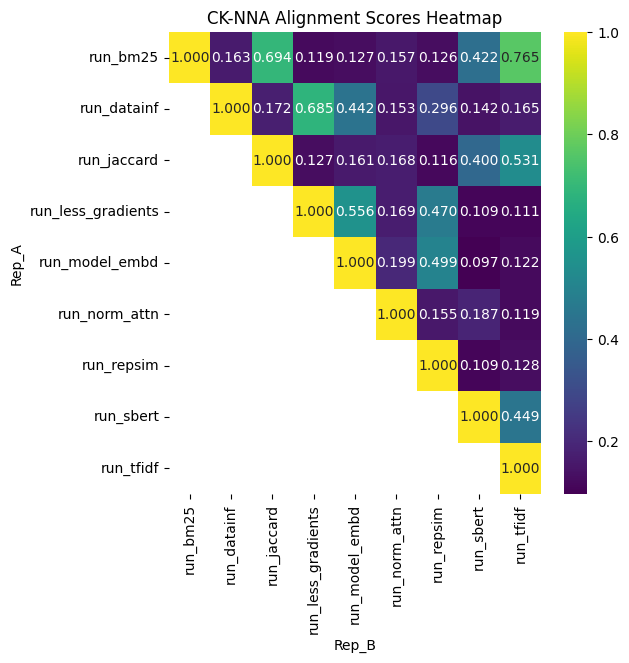

In [5]:
import torch
import torch.nn.functional as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from metrics import AlignmentMetrics
from itertools import combinations

# Dictionary of feature sets

# Normalize all feature sets on GPU
features = {k: F.normalize(v, dim=-1) for k, v in features.items()}

# Compute pairwise CK-NNA scores
results = []
for (name1, feat1), (name2, feat2) in combinations(features.items(), 2):
    
    score = AlignmentMetrics.cknna(feat1.cpu(), feat2.cpu(), topk=10)
    results.append((name1, name2, score))
    results.append((name2, name1, score))  # fill symmetric entry

# Add diagonal entries (self-similarity)
for name, feat in features.items():
    results.append((name, name, 1.0))  # CK-NNA score with self = 1.0

# Convert to DataFrame
df_scores = pd.DataFrame(results, columns=["Rep_A", "Rep_B", "CKNNA_score"])

heatmap_data = df_scores.pivot(index="Rep_A", columns="Rep_B", values="CKNNA_score")

mask = np.tril(np.ones_like(heatmap_data, dtype=bool), k=-1)  # k=-1 keeps diagonal

plt.figure(figsize=(6, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="viridis", mask=mask)
plt.title("CK-NNA Alignment Scores Heatmap")
plt.show()

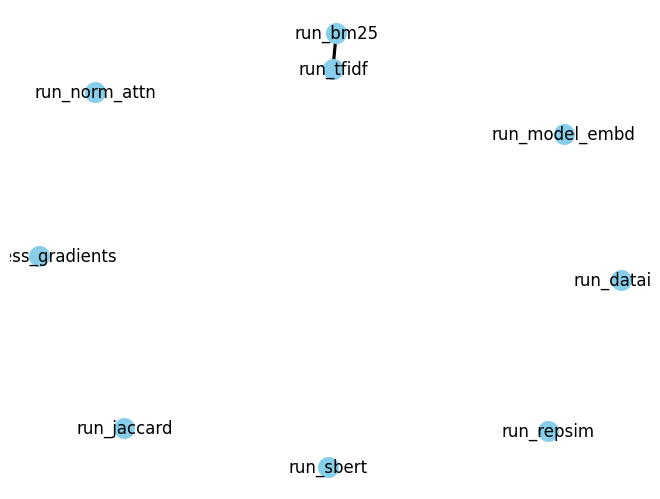

In [4]:
import networkx as nx

G = nx.Graph()


for name in heatmap_data.index:
    G.add_node(name)


threshold = 0.7
for i, name1 in enumerate(heatmap_data.index):
    for j, name2 in enumerate(heatmap_data.columns):
        if i < j and heatmap_data.loc[name1, name2] > threshold:
            G.add_edge(name1, name2, weight=heatmap_data.loc[name1, name2])

# Draw graph
pos = nx.spring_layout(G, seed=42)
edges = G.edges()
weights = [G[u][v]['weight']*3 for u,v in edges]  # scale weights
nx.draw(G, pos, with_labels=True, width=weights, node_size=200, node_color="skyblue")

plt.show()